# Ronda012b — decisiones multiclase
Accuracy principal; F1 macro control. Resultados de selección sobre datos ya explorados.

In [1]:
from pathlib import Path
import os,json
import pandas as pd
from IPython.display import display,Markdown
if not Path('reports/registro_012b.json').exists():os.chdir('..')
r=json.loads(Path('reports/registro_012b.json').read_text())
display(Markdown(Path('reports/resumen_012b.md').read_text()))
cv=pd.read_csv('reports/resultados_012b.csv');display(cv)
display(pd.read_csv('reports/criterios_012b.csv'));display(r['historical'])

# Ronda012b — auditoría011 y decisiones multiclase

Accuracy principal y F1 macro control por autorización del usuario. Score visible011: **0,89888**, frente a010:0,89777. Score012 desconocido.

## Qué cambió en011

Los coeficientes de011 son idénticos a010: LinearSVC L1 C=2 y las mismas características. El cambio es sumar0,2 a los márgenes positivo y negativo antes del argmax. Solo4 de3000 predicciones cambian. La subida pública es0,00111; no permite identificar los aciertos públicos ni demostrar un techo de rendimiento.

El artefacto modelo_011.joblib guarda el clasificador base sin esa regla: su predict() difiere del CSV en4filas. La regla se aplica en producir_011.py. La nueva referencia encapsula ambos componentes en predict() y usa nombres de clase. Los artefactos previos no se modifican. El script anterior sí reentrena la base, aunque el informe decía que no; se verificó igualdad de coeficientes.

## Métodos investigados e implementados

- `ref011`: reproducción de011 con descuento neutral0,2.
- `polarity_c1` y `polarity_c2`: conservan exactamente la puerta neutral011; un SVM binario decide positivo/negativo, entrenado solo con ejemplos polares del entrenamiento.
- `ovo_l1`: tres clasificadores entre pares de clases y combinación de decisiones, todos L1 C=2.
- `sigmoid`: calibración con predicciones internas fuera de fold; tres particiones internas agrupadas, vocabulario/IDF dentro de cada ajuste y refit final de la base. Sin descuento manual adicional.

Fuentes y protocolo: [investigacion_012b.md](investigacion_012b.md), [OneVsOneClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.multiclass.OneVsOneClassifier.html) y [CalibratedClassifierCV](https://scikit-learn.org/stable/modules/generated/sklearn.calibration.CalibratedClassifierCV.html). No se añadieron datos externos ni sintéticos.

## Resultados locales de selección

| Candidata | Accuracy media OOF | F1 macro medio OOF | Brecha accuracy | Folds ganados |
|---|---:|---:|---:|---:|
| ref011 | 0.900243 | 0.904792 | 0.088056 | — |
| sigmoid | 0.900104 | 0.904595 | 0.088194 | 2/9 |
| polarity_c2 | 0.897014 | 0.901720 | 0.088316 | 0/9 |
| ovo_l1 | 0.895590 | 0.900167 | 0.089115 | 0/9 |
| polarity_c1 | 0.895208 | 0.899998 | 0.057222 | 1/9 |

Las medias OOF promedian los resultados de9600 predicciones de desarrollo por semilla. La brecha es accuracy de entrenamiento menos validación, promediada entre folds. Son las mismas particiones para todas las candidatas.

## Criterios y decisión

>=7/9 folds accuracy; delta medio accuracy >=0.001; delta F1 medio >=0; aumento brecha accuracy media <=0.005; no perder accuracy ni F1 en137.

Umbral de ganancia0.001 y tolerancia de brecha0.005 fijados antes de medir esta ronda; distintos de011b. No implican significación ni ausencia de sobreajuste.

Este es un protocolo nuevo, más sensible a mejoras pequeñas que011b; no se reclasifican retrospectivamente los resultados de esa ronda. Las condiciones se fijaron antes de medir012b y no se relajaron después.

Ganadora: **ninguna**. CSV creado: **False**.

Conservar011: ninguna candidata supera los criterios. No crear un envío equivalente ni bajar umbrales a posteriori.

## Controles y límites

Las9600 filas de desarrollo son las únicas usadas para seleccionar. El test local histórico no se reutiliza para decidir; eval se usa únicamente para auditar artefactos anteriores y exportar después de decidir. Grupos de texto normalizado disjuntos. Vocabulario, IDF, clasificadores y calibración aprendidos dentro del entrenamiento correspondiente; convergencia exigida. La calibración interna se rehace dentro de cada fold externo.

Hay selección adaptativa acumulada sobre este dataset: nuevas semillas no crean datos vírgenes. La CV interna evita fuga del fold externo al calibrador, pero no elimina el sesgo de elegir entre alternativas tras muchas rondas. Los nueve folds repetidos no son independientes. Una brecha menor no demuestra ausencia de sobreajuste y una tolerancia de0,005 no significa que ningún aumento sea aceptable universalmente.

El registro previo011 declara una calibración anidada de su descuento, pero no se localizaron tablas/código de esas semillas en esta revisión. La exportación011 sí se verificó, y la nueva comparación es reproducible. No se asume que frecuencia de clases justifique automáticamente descontar un margen SVM. No se promete0,90 público ni se concluye un techo absoluto del ML clásico.

## Reproducibilidad

Tiempo: 932.8 segundos. Artefactos anteriores intactos: True.

`.venv/bin/python -m src.experimento_012b` (protege destinos existentes), `.venv/bin/python -m src.verificar_012b` y `.venv/bin/python -m src.informe_012b`. El notebook analiza resultados guardados; no vuelve a entrenar. Ver plan, registro, criterios, folds y predicciones_oof con sufijo012b.


,name,seed,accuracy,f1,gap
0,ref011,8803,0.901875,0.906381,0.086458
1,polarity_c1,8803,0.897604,0.902319,0.055000
2,polarity_c2,8803,0.900104,0.904697,0.084531
3,ovo_l1,8803,0.898542,0.903010,0.085573
4,sigmoid,8803,0.901875,0.906313,0.086406
5,ref011,9901,0.900000,0.904527,0.087969
6,polarity_c1,9901,0.894479,0.899267,0.056719
7,polarity_c2,9901,0.896146,0.900856,0.089479
8,ovo_l1,9901,0.894896,0.899464,0.090052
9,sigmoid,9901,0.899583,0.904060,0.088437


,name,accuracy_gain,f1_gain,gap_change,folds_won,passes
0,polarity_c1,-0.005035,-0.004794,-0.030833,1,False
1,polarity_c2,-0.003229,-0.003072,0.000260,0,False
2,ovo_l1,-0.004653,-0.004626,0.001059,0,False
3,sigmoid,-0.000139,-0.000198,0.000139,2,False


{}

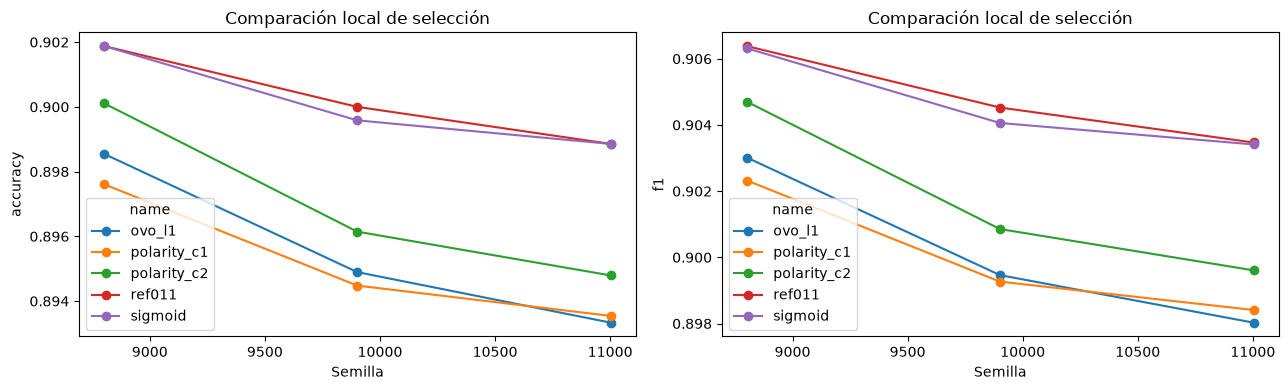

,name,seed,fold,train_accuracy,validation_accuracy,train_f1,validation_f1,gap,seconds
0,ref011,8803,0,0.986563,0.898438,0.987239,0.903307,0.088125,8.346959
1,ref011,8803,1,0.989688,0.901563,0.990207,0.905839,0.088125,9.417825
2,ref011,8803,2,0.988750,0.905625,0.989314,0.909998,0.083125,9.087412
3,polarity_c1,8803,0,0.954688,0.890938,0.956969,0.896188,0.063750,11.505837
4,polarity_c1,8803,1,0.952969,0.895938,0.955334,0.900485,0.057031,12.202093
5,polarity_c1,8803,2,0.950156,0.905937,0.952655,0.910290,0.044219,12.275179
6,polarity_c2,8803,0,0.981875,0.898125,0.982788,0.903014,0.083750,11.919625
7,polarity_c2,8803,1,0.986094,0.900000,0.986794,0.904349,0.086094,12.989431
8,polarity_c2,8803,2,0.985938,0.902188,0.986643,0.906733,0.083750,13.767355
9,ovo_l1,8803,0,0.981563,0.895625,0.982464,0.900263,0.085938,6.375255


In [2]:
import matplotlib.pyplot as plt
main=cv[cv.seed.isin(r['plan']['seeds'])]
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,metric in zip(axes,['accuracy','f1']):
 main.pivot(index='seed',columns='name',values=metric).plot(marker='o',ax=ax)
 ax.set(xlabel='Semilla',ylabel=metric,title='Comparación local de selección')
plt.tight_layout();plt.savefig('reports/comparacion_012b.png',dpi=160);plt.show()
display(pd.read_csv('reports/folds_012b.csv'))

In [3]:
display(r['source_sha256'])
print('Artefactos anteriores intactos:',r['old_artifacts_unchanged'])
if r['submission_created']:
 display(r['artifacts_sha256']);display(pd.read_csv('submissions/submission_012.csv').head())
else:print(r['decision'])

{'src/experimento_012b.py': '08602584581890ff8972db08fa9276b465cacd59d3e9d63c4398b6ab2aed62aa',
 'src/modelos_012b.py': '91757138d193b72799f66320ce857b7f4b647040b60267a37c4b0c526828903b',
 'src/experimento.py': '0740def773bb28f19f896485f1db81175f4e81feac01f6a894d83aba43923d7b',
 'src/features_007b.py': '32168dc3045b8b146e3260ddfb8b04c3153e1210ade017050ec2243fe7c3daa3',
 'reports/particiones.csv': 'd90cbd30a92a366298a66f2322df4869694798392f19b9c0978dbecac104a931'}

Artefactos anteriores intactos: True
Conservar011: ninguna candidata supera los criterios. No crear un envío equivalente ni bajar umbrales a posteriori.
